#3

In [1]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))
DB = "utsgsd"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke database:", DB)

Terhubung ke database: utsgsd


In [2]:
import pandas as pd

def run(query, **params):
    records, _, _ = driver.execute_query(query, database_=DB, **params)
    return pd.DataFrame([dict(r) for r in records])

In [3]:
q = "MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah"
print(q)
run(q)

MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah


,label,jumlah
0,[Visitor],681413
1,[Item],170615


In [4]:
q = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"
print(q)
run(q)

MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah


,relasi,jumlah
0,VIEWED,1272750
1,ADDED_TO_CART,32681
2,BOUGHT,10829


In [5]:
q = """
MATCH (v:Visitor)-[:BOUGHT]->(i:Item)
RETURN count(DISTINCT v) AS visitor_beli, count(DISTINCT i) AS item_dibeli
"""
print(q)
run(q)


MATCH (v:Visitor)-[:BOUGHT]->(i:Item)
RETURN count(DISTINCT v) AS visitor_beli, count(DISTINCT i) AS item_dibeli



,visitor_beli,item_dibeli
0,5633,6740


### Penjelasan Cypher

**1. `MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah`**
- `MATCH (n)` mengambil semua simpul.
- `labels(n)` mengembalikan jenis simpul (`Visitor` atau `Item`).
- `count(*)` menghitung jumlahnya. Karena `labels(n)` ikut di `RETURN`,
  Neo4j otomatis mengelompokkan hasil per label (seperti GROUP BY di SQL).

**2. `MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah`**
- `()-[r]->()` adalah pola: simpul apa pun, relasi `r`, simpul apa pun.
- `type(r)` mengembalikan jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

**3. `count(DISTINCT v)`**
- Menghitung visitor unik, bukan jumlah pembeliannya.

### Interpretasi
- Graf bersifat **bipartit**: ada dua jenis simpul (Visitor dan Item),
  relasi hanya dari Visitor ke Item.
- Jumlah relasi sesuai hasil filter P1:
  VIEWED 1.272.750, ADDED_TO_CART 32.681, BOUGHT 10.829.
- (isi jumlah Visitor dan Item dari hasil Cell 3)
- Visitor yang pernah membeli jauh lebih sedikit dibanding total visitor,
  jadi data sangat sparse.

#4

In [6]:
%pip install scipy networkx matplotlib scikit-learn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   - -------------------------------------- 1.6/36.7 MB 7.6 MB/s eta 0:00:05
   ---- ----------------------------------- 3.7/36.7 MB 9.1 MB/s eta 0:00:04
   ------- -------------------------------- 6.8/36.7 MB 10.7 MB/s eta 0:00:03
   --------- ------------------------------ 8.4/36.7 MB 10.0 MB/s eta 0:00:03
   -------------- ------------------------- 13.1/36.7 MB 12.6 MB/s eta 0:00:02
   --------------------- ------------------ 19.4/36.7 MB 15.5 MB/s eta 0:00:02
   ----------------------------- ---------- 27.3/36.7 MB 18.6 MB/s eta 0:00:01
   -------------------------------------- - 35.7/36.7 MB 21.2 MB/s eta 0:00:01
   ---------------------------------------- 36.7/36.7 MB 20.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 29.8 MB/s eta 0:00:00
   ------------


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

In [8]:
q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS n
"""
records, _, _ = driver.execute_query(q, database_=DB)
edges = pd.DataFrame([dict(r) for r in records])

# bobot per jenis interaksi (asumsi, jelaskan di laporan)
W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["t"].map(W) * edges["n"]
edges = edges.groupby(["u", "i"], as_index=False)["w"].sum()

ucat = pd.Categorical(edges["u"])
icat = pd.Categorical(edges["i"])
users = ucat.categories.values
items = icat.categories.values

U = sp.csr_matrix(
    (edges["w"].values, (ucat.codes, icat.codes)),
    shape=(len(users), len(items)),
)
print("Shape U (user x item):", U.shape)

Shape U (user x item): (681413, 170615)


In [10]:
n_u, n_i = U.shape
deg_u = np.diff(U.indptr)           # jumlah item berbeda per user
print("Dimensi vektor user :", n_i)
print("Jumlah vektor (user):", n_u)
print("Nilai non-nol       :", U.nnz)
print("Density             :", U.nnz / (n_u * n_i))
print("Sparsity            :", 1 - U.nnz / (n_u * n_i))
print("Memori jika dense   : %.1f GB" % (n_u * n_i * 8 / 1e9))
print("Memori sparse       : %.1f MB" % ((U.data.nbytes + U.indices.nbytes + U.indptr.nbytes) / 1e6))
print(pd.Series(deg_u).describe())

Dimensi vektor user : 170615
Jumlah vektor (user): 681413
Nilai non-nol       : 1025824
Density             : 8.823588180381868e-06
Sparsity            : 0.9999911764118197
Memori jika dense   : 930.1 GB
Memori sparse       : 15.0 MB
count    681413.000000
mean          1.505436
std           6.334803
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        2636.000000
dtype: float64


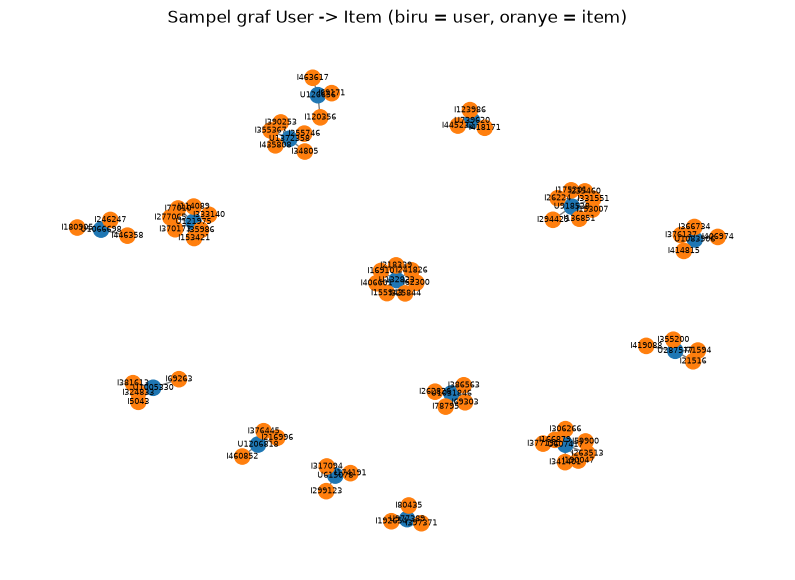

In [11]:
def plot_bipartite(M, row_names, col_names, row_tag, col_tag, n=15, seed=42, title=""):
    rng = np.random.default_rng(seed)
    deg = np.diff(M.indptr)
    cand = np.where((deg >= 3) & (deg <= 8))[0]
    pick = rng.choice(cand, size=min(n, len(cand)), replace=False)

    G = nx.Graph()
    row_nodes = set()
    for r in pick:
        rn = f"{row_tag}{row_names[r]}"
        row_nodes.add(rn)
        for c in M.indices[M.indptr[r]:M.indptr[r + 1]]:
            G.add_edge(rn, f"{col_tag}{col_names[c]}")

    colors = ["tab:blue" if x in row_nodes else "tab:orange" for x in G.nodes]
    plt.figure(figsize=(10, 7))
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=seed),
                     node_color=colors, node_size=120, font_size=6, edge_color="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

plot_bipartite(U, users, items, "U", "I",
               title="Sampel graf User -> Item (biru = user, oranye = item)")

#5

In [12]:
Ui = U.T.tocsr()                    # item x user
deg_i = np.diff(Ui.indptr)          # jumlah user berbeda per item

print("Shape Ui (item x user):", Ui.shape)
print("Dimensi vektor item   :", Ui.shape[1])
print("Jumlah vektor (item)  :", Ui.shape[0])
print("Nilai non-nol         :", Ui.nnz)
print("Density               :", Ui.nnz / (Ui.shape[0] * Ui.shape[1]))
print("Sparsity              :", 1 - Ui.nnz / (Ui.shape[0] * Ui.shape[1]))
print("Memori jika dense     : %.1f GB" % (Ui.shape[0] * Ui.shape[1] * 8 / 1e9))
print(pd.Series(deg_i).describe())

Shape Ui (item x user): (170615, 681413)
Dimensi vektor item   : 681413
Jumlah vektor (item)  : 170615
Nilai non-nol         : 1025824
Density               : 8.823588180381868e-06
Sparsity              : 0.9999911764118197
Memori jika dense     : 930.1 GB
count    170615.000000
mean          6.012508
std          15.483407
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max        1615.000000
dtype: float64


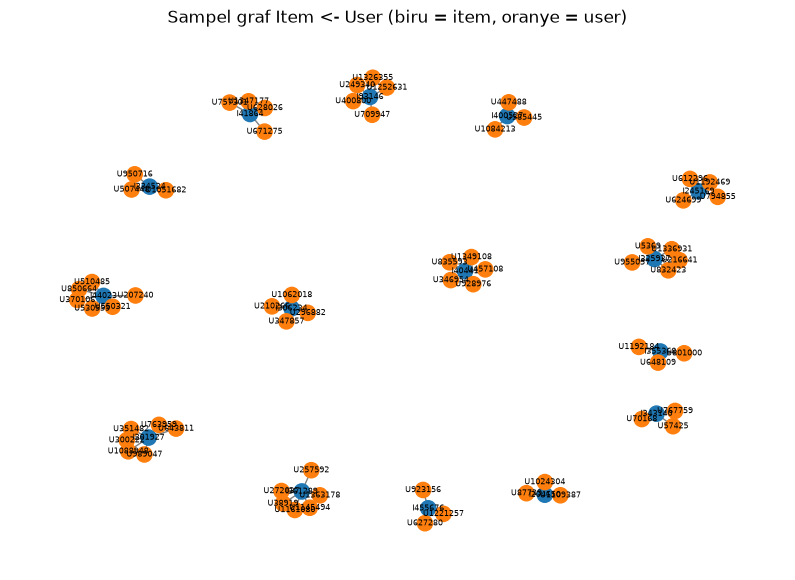

In [13]:
plot_bipartite(Ui, items, users, "I", "U",
               title="Sampel graf Item <- User (biru = item, oranye = user)")

In [14]:
top_items = pd.DataFrame({"itemId": items, "jumlah_user": deg_i}) \
              .sort_values("jumlah_user", ascending=False).head(10)
top_items

,itemId,jumlah_user
1968,5411,1615
113277,309778,742
135527,370653,658
122864,335975,631
108994,298009,610
94051,257040,576
140584,384302,566
129579,354233,564
80301,219512,562
168744,461686,549


#6

In [15]:
cost_user_proj = float((deg_i.astype("float64") ** 2).sum())   # U @ U.T
cost_item_proj = float((deg_u.astype("float64") ** 2).sum())   # U.T @ U

tabel = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Ukuran matriks": [f"{n_u} x {n_u}", f"{n_i} x {n_i}"],
    "Memori dense (GB)": [n_u**2 * 8 / 1e9, n_i**2 * 8 / 1e9],
    "Perkiraan operasi": [cost_user_proj, cost_item_proj],
})
tabel

,Proyeksi,Ukuran matriks,Memori dense (GB),Perkiraan operasi
0,User-User,681413 x 681413,3714.589413,47070074.0
1,Item-Item,170615 x 170615,232.875826,28889190.0


In [16]:
Un = normalize(Ui)   # L2 per baris (per item)

def topk_similar(Mn, idx, k=5):
    s = (Mn @ Mn[idx].T).toarray().ravel()
    s[idx] = -1                                   # abaikan diri sendiri
    top = np.argpartition(-s, k)[:k]
    top = top[np.argsort(-s[top])]
    return top, s[top]

In [17]:
rng = random.Random(42)
cand = np.where((deg_i >= 20) & (deg_i <= 100))[0]
ref_idx = int(rng.choice(list(cand)))
ref_id = int(items[ref_idx])
print("Item acuan itemId:", ref_id, "| dilihat oleh", deg_i[ref_idx], "user")

top_idx, top_sim = topk_similar(Un, ref_idx, k=5)
hasil = pd.DataFrame({"itemId": items[top_idx], "similarity": top_sim})
hasil

Item acuan itemId: 89379 | dilihat oleh 43 user


,itemId,similarity
0,37972,0.285714
1,169924,0.285714
2,110489,0.285714
3,110653,0.285714
4,275217,0.285714


In [18]:
sebelum = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah")
sebelum

,relasi,jumlah
0,VIEWED,1272750
1,ADDED_TO_CART,32681
2,BOUGHT,10829


In [19]:
rows = [{"b": int(i), "score": float(s)} for i, s in zip(items[top_idx], top_sim)]
q_write = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $a}), (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
driver.execute_query(q_write, rows=rows, a=ref_id, database_=DB)
print("Relasi SIMILAR_TO ditulis")

Relasi SIMILAR_TO ditulis


In [20]:
q_top5 = """
MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
print(q_top5)
run(q_top5, id=ref_id)


MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5



,item,similarity
0,110653,0.285714
1,169924,0.285714
2,110489,0.285714
3,275217,0.285714
4,37972,0.285714


In [21]:
sesudah = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah")
pd.concat([sebelum.set_index("relasi"), sesudah.set_index("relasi")],
          axis=1, keys=["sebelum", "sesudah"])

,sebelum,sesudah
,jumlah,jumlah
relasi,,
VIEWED,1272750.0,1272750
ADDED_TO_CART,32681.0,32681
BOUGHT,10829.0,10829
SIMILAR_TO,NaN,5
